# Notebook 02: The exact answer and the value map

**Project:** Hacker Statistics, chances of winning a bet  
**Notebook 01** simulated the bet and found that about 78 in 100 climbers reach step 60. This notebook asks a harder question: **what is the true chance, with no randomness at all?** Then it uses the same math to build a *value map* that shows the chance of winning from every position in the game.

**The game, in one paragraph.** You start on step 0 and roll a die 100 times. A 1 or 2 moves you down one step (never below 0). A 3, 4 or 5 moves you up one. A 6 means you roll again and climb that many steps. After every roll there is a 0.1% chance you are clumsy and fall all the way back to step 0. You win if you finish the 100 rolls on step 60 or higher.

**How each section is laid out:** what we are looking for, the code, its result, how to read it, what it means, and what's next and why.

## 1. Setup

### What we are looking for
A working environment: the project's own functions (`src/hacker_stats.py`), NumPy for the math and Matplotlib for charts. The chart colours match the project website so the notebook and the site look like one piece of work.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Find the project folder whether PyCharm runs this notebook from the project root or from notebooks/
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.hacker_stats import (simulate, win_chance, exact_distribution,
                              exact_win_chance, value_map, wilson_interval)

# Project colours (same as the website)
RED, BLUE, GREY, GOLD = "#9A3B2E", "#2F6690", "#a39b93", "#A87613"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

ROLLS, TARGET, CLUMSY = 100, 60, 0.001
print("Setup complete. Game: roll", ROLLS, "times, win at step", TARGET, "or higher, clumsiness", CLUMSY)

Setup complete. Game: roll 100 times, win at step 60 or higher, clumsiness 0.001


### How to read it
Nothing to interpret yet. The last line just confirms the three rules of the game that every later cell uses.

### What it means
Every number in this notebook comes from the same three settings: 100 rolls, a target of step 60 and a 0.1% chance of falling to 0. Change them here and every later result updates.

### What's next and why
Next we repeat the simulation from notebook 01 so we have an answer to check the exact math against.

## 2. The simulated answer (hacker statistics)

### What we are looking for
One estimate of the chance of winning from simulation: play the game 10,000 times and count how many climbers finish on step 60 or higher. We also want an honest margin of error, because a simulation gives an estimate, not the truth.

In [2]:
N_WALKS = 10_000
paths = simulate(walks=N_WALKS, rolls=ROLLS, clumsy=CLUMSY, seed=123)   # one row per climber
sim_chance = win_chance(paths, TARGET)
low, high = wilson_interval(int(round(sim_chance * N_WALKS)), N_WALKS)

print(f"Climbers simulated:        {N_WALKS:,}")
print(f"Finished on step {TARGET}+:     {int(round(sim_chance * N_WALKS)):,}")
print(f"Simulated chance of win:   {sim_chance:.2%}")
print(f"95% confidence interval:   {low:.2%} to {high:.2%}")

Climbers simulated:        10,000
Finished on step 60+:     7,755
Simulated chance of win:   77.55%
95% confidence interval:   76.72% to 78.36%


### How to read it
The simulated chance is the share of the 10,000 climbers who won. The 95% confidence interval is the range of true chances that would plausibly produce what we saw. Here it runs from 76.7% to 78.4%, a little under a point on each side of the estimate, which is the normal price of using 10,000 climbers.

### What it means
Simulation says the true chance is somewhere between roughly 76.7% and 78.4%. That is a good answer, but it is a range, and a different random seed would move the middle of it.

### What's next and why
Now we compute the chance exactly. If the exact number lands inside this range, that confirms the simulation was working correctly.

## 3. The exact answer (a Markov chain)

### What we are looking for
The true probability of every possible finishing step, and from that the true chance of winning. The key idea: where you can be after roll *n + 1* depends only on where you are after roll *n*, not on how you got there. A process like that is called a Markov chain, and it lets us skip the random numbers completely. We carry a list of probabilities, one per step, and update the whole list once per roll.

In [3]:
final = exact_distribution(rolls=ROLLS, clumsy=CLUMSY)       # final[s] = chance of finishing exactly on step s
exact_chance = final[TARGET:].sum()                          # add up every step from 60 upward

print(f"Probabilities add up to:     {final.sum():.10f}   (must be 1)")
print(f"Exact chance of winning:     {exact_chance:.4%}")
print(f"Simulated chance (section 2): {sim_chance:.2%}")
print(f"Difference:                  {abs(exact_chance - sim_chance) * 100:.2f} percentage points")
print(f"Exact interval check:        {low:.2%} <= {exact_chance:.2%} <= {high:.2%}  ->  {low <= exact_chance <= high}")
print(f"Average finishing step:      {(np.arange(len(final)) * final).sum():.1f}")

Probabilities add up to:     1.0000000000   (must be 1)
Exact chance of winning:     77.6691%
Simulated chance (section 2): 77.55%
Difference:                  0.12 percentage points
Exact interval check:        76.72% <= 77.67% <= 78.36%  ->  True
Average finishing step:      72.1


### How to read it
The first line is a sanity check: the probabilities of all possible finishing steps must add to exactly 1, and they do. The exact chance of winning is 77.67%. The simulation said 77.55%, a gap of about 0.1 percentage points, and the exact value sits well inside the simulation's confidence interval.

### What it means
The simulation was right, and now we know how right: its error was about 0.1 points out of 100. The exact answer also needed no random numbers, so it is the same every time you run it. The average climber finishes around step 72, comfortably past the target of 60, which is why most climbers win.

### What's next and why
A single comparison could be luck. Next we compare the whole shape of the results, not just the win chance.

## 4. Does the whole distribution match?

### What we are looking for
A picture of where climbers finish. The bars are the simulation (10,000 climbers). The line is the exact probability for each step. If the simulation is trustworthy, the bars should follow the line.

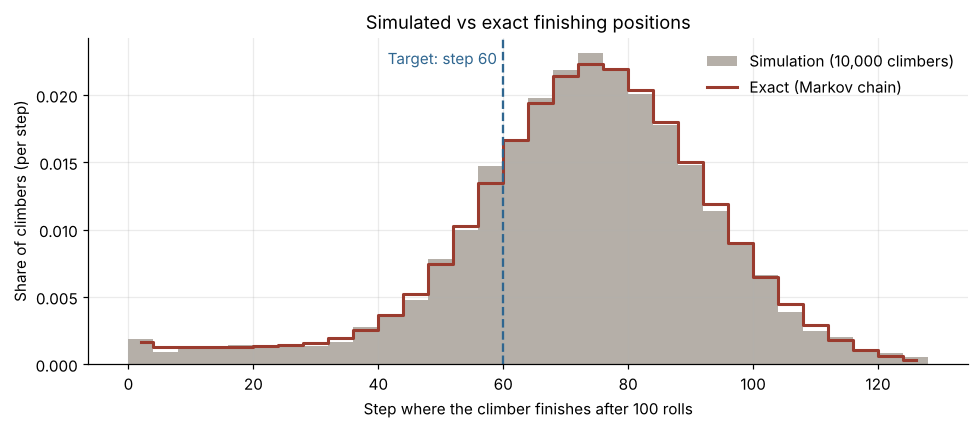

Chance of finishing below 20: 2.76% (mostly climbers who were clumsy late in the game)


In [4]:
ends = paths[:, -1]
bins = np.arange(0, 130, 4)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(ends, bins=bins, density=True, color=GREY, alpha=0.8, label="Simulation (10,000 climbers)")

# Exact probabilities, grouped into the same 4-step bins and scaled to match the histogram
grouped = np.array([final[a:a + 4].sum() / 4 for a in bins[:-1]])
ax.step(bins[:-1] + 2, grouped, where="mid", color=RED, lw=2, label="Exact (Markov chain)")

ax.axvline(TARGET, color=BLUE, ls="--", lw=1.5)
ax.text(TARGET - 1, ax.get_ylim()[1] * 0.92, f"Target: step {TARGET}", color=BLUE, ha="right")
ax.set_xlabel("Step where the climber finishes after 100 rolls")
ax.set_ylabel("Share of climbers (per step)")
ax.set_title("Simulated vs exact finishing positions")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print("Chance of finishing below 20:", f"{final[:20].sum():.2%}", "(mostly climbers who were clumsy late in the game)")

### How to read it
Grey bars are what the simulation found; the red line is the exact answer. The blue dashed line is the target. Everything to the right of it is a win. The low, flat stretch on the left comes mostly from clumsiness: a climber who falls to step 0 late in the game does not have time to climb back.

### What it means
The red line runs through the tops of the bars, so the simulation matches the exact answer across the whole range, not just at one number. The wins are the large hump on the right. The thin tail at the far left is the cost of being clumsy near the end of the game: about 2.8% of climbers finish below step 20.

### What's next and why
We said the simulation's error should shrink as we add climbers. Next we test that claim directly, because it tells us how many simulated climbers are enough.

## 5. How many simulated climbers are enough?

### What we are looking for
How the simulation's error shrinks as the number of climbers grows. Because we now know the exact answer, we can measure the error directly: for each size, run 20 different simulations and see how far each one lands from the truth.

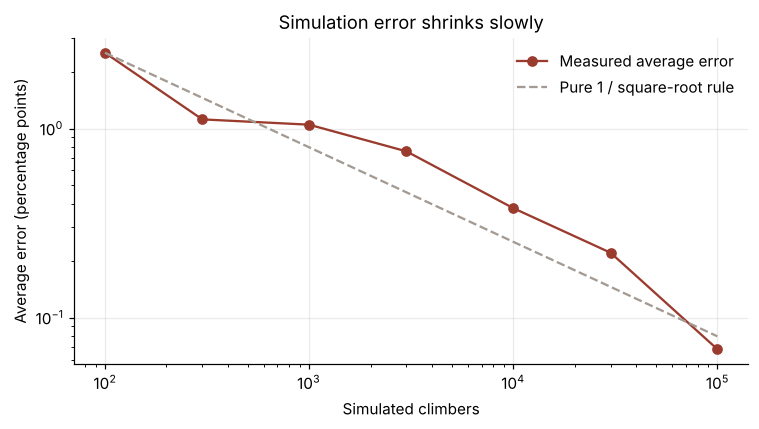

     100 climbers: average error 2.52 percentage points
     300 climbers: average error 1.12 percentage points
   1,000 climbers: average error 1.05 percentage points
   3,000 climbers: average error 0.76 percentage points
  10,000 climbers: average error 0.38 percentage points
  30,000 climbers: average error 0.22 percentage points
 100,000 climbers: average error 0.07 percentage points


In [5]:
sizes = [100, 300, 1_000, 3_000, 10_000, 30_000, 100_000]
mean_error = []
for n in sizes:
    errs = [abs(win_chance(simulate(n, ROLLS, CLUMSY, seed=s), TARGET) - exact_chance) for s in range(20)]
    mean_error.append(np.mean(errs))

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(sizes, np.array(mean_error) * 100, "o-", color=RED, label="Measured average error")
ref = mean_error[0] * 100 * np.sqrt(sizes[0] / np.array(sizes))
ax.loglog(sizes, ref, "--", color=GREY, label="Pure 1 / square-root rule")
ax.set_xlabel("Simulated climbers")
ax.set_ylabel("Average error (percentage points)")
ax.set_title("Simulation error shrinks slowly")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

for n, e in zip(sizes, mean_error):
    print(f"{n:>8,} climbers: average error {e * 100:.2f} percentage points")

### How to read it
Both axes are logarithmic, so a straight line means a steady rule. The red line (measured error) falls roughly along the grey dashed line, the textbook rule that error shrinks with the square root of the number of climbers. It is a little bumpy because each point averages only 20 simulations.

### What it means
Making the simulation ten times larger cuts the error only about threefold. Going from 1,000 to 100,000 climbers (100 times more work) cuts the average error from about 1.05 points to 0.07 points. That is the weakness of hacker statistics: precision is expensive. The exact method has zero error for the price of a few hundred additions.

### What's next and why
The exact method can do more than one number. Next we turn it around and ask, from any position in the game, what are your chances?

## 6. The value map

### What we are looking for
So far we only asked about the start of the game. A **value map** answers a bigger question: *if I am on step s after roll t, what is my chance of still winning?* We compute it by working backwards from the last roll, where the answer is simply "yes" at step 60 or higher and "no" below. Each earlier roll is then the average of the possible next positions. In reinforcement learning this table is called a value function, and this backwards method is dynamic programming.

In [6]:
V = value_map(rolls=ROLLS, target=TARGET, clumsy=CLUMSY)    # V[t, s]

print(f"Chance of winning from the very start (roll 0, step 0): {V[0, 0]:.4%}")
print(f"Same number from the forward calculation (section 3):  {exact_chance:.4%}")
print()
examples = [("Roll 30, step 40 (well ahead)", 30, 40),
            ("Roll 30, step 20 (behind)", 30, 20),
            ("Roll 50, step 50 (late and just short)", 50, 50),
            ("Roll 80, step 40 (far behind, late)", 80, 40),
            ("Roll 99, step 59 (one roll left, one short)", 99, 59),
            ("Roll 99, step 60 (one roll left, on the target)", 99, 60)]
for label, t, s in examples:
    print(f"{label:<50} {V[t, s]:>7.1%}")

Chance of winning from the very start (roll 0, step 0): 77.6691%
Same number from the forward calculation (section 3):  77.6691%

Roll 30, step 40 (well ahead)                        92.9%
Roll 30, step 20 (behind)                            77.0%
Roll 50, step 50 (late and just short)               94.6%
Roll 80, step 40 (far behind, late)                  25.9%
Roll 99, step 59 (one roll left, one short)          66.6%
Roll 99, step 60 (one roll left, on the target)      66.6%


### How to read it
The first two lines are a strong check. We reached the same number, 77.67%, by two completely different routes: forward through the probabilities of finishing steps (section 3), and backward through the value map. They agree to every digit shown.

The examples below them show how the chance moves with position. Being 40 steps up after 30 rolls gives 93%. Being on step 20 at the same time is still 77%, almost the starting chance, because there are 70 rolls left to catch up. But step 40 at roll 80 gives only 26%, because time has run out.

### What it means
**Time matters as much as height.** The same step is worth very different amounts depending on how many rolls remain. The last two examples show something easy to miss: standing exactly on step 60 with one roll left is only 66.6% to win, not 100%, because the next roll can send you down. You win only if you are still at 60 or higher after the final roll.

### What's next and why
Numbers one at a time are hard to take in. Next we draw the whole map so the pattern is visible.

## 7. Drawing the whole map

### What we are looking for
The chance of winning for every combination of roll number (left to right) and current step (bottom to top). Dark blue means the win is nearly certain, light grey means it is nearly lost. We also draw two contour lines: the steps where the chance is 50% and 90%.

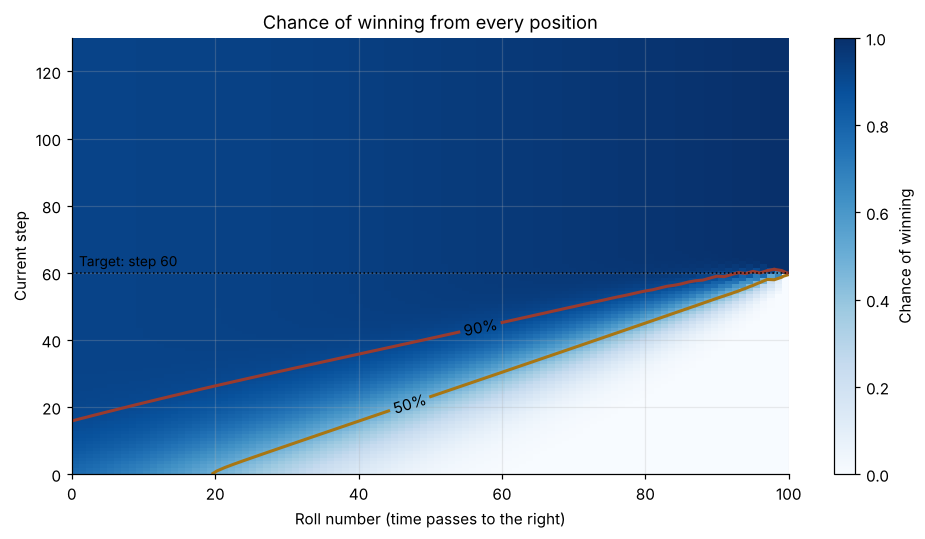

Step you need to be on for a 50% / 90% chance of winning:
  after roll 10:  50% needs step  0,   90% needs step 22
  after roll 25:  50% needs step  5,   90% needs step 29
  after roll 50:  50% needs step 24,   90% needs step 41
  after roll 75:  50% needs step 42,   90% needs step 53
  after roll 90:  50% needs step 53,   90% needs step 60
  after roll 99:  50% needs step 59,   90% needs step 61


In [7]:
max_step = 130
view = V[:, :max_step + 1].T            # rows = step, columns = roll

fig, ax = plt.subplots(figsize=(9, 5))
img = ax.imshow(view, origin="lower", aspect="auto", cmap="Blues", vmin=0, vmax=1,
                extent=[0, ROLLS, 0, max_step])
cs = ax.contour(np.arange(ROLLS + 1), np.arange(max_step + 1), view, levels=[0.5, 0.9],
                colors=[GOLD, RED], linewidths=2)
ax.clabel(cs, fmt={0.5: "50%", 0.9: "90%"}, fontsize=10, colors="black")
ax.axhline(TARGET, color="black", ls=":", lw=1)
ax.text(1, TARGET + 2, f"Target: step {TARGET}", fontsize=9)
ax.set_xlabel("Roll number (time passes to the right)")
ax.set_ylabel("Current step")
ax.set_title("Chance of winning from every position")
fig.colorbar(img, ax=ax, label="Chance of winning")
plt.tight_layout()
plt.show()

print("Step you need to be on for a 50% / 90% chance of winning:")
for t in [10, 25, 50, 75, 90, 99]:
    row = V[t, :400]
    print(f"  after roll {t:>2}:  50% needs step {int(np.argmax(row >= 0.5)):>2},   90% needs step {int(np.argmax(row >= 0.9)):>2}")

### How to read it
Find your roll number along the bottom and your step up the side; the colour where they meet is your chance of winning. The gold line is the 50% boundary and the red line is the 90% boundary. Above red you are very likely to win; below gold you are more likely to lose.

The table underneath turns the lines into numbers. After roll 10 you need to be on step 22 for a 90% chance. After roll 50 you need step 41. After roll 90 you need step 60, and after roll 99 you need step 61, because one roll left means you must already have a cushion.

### What it means
The boundaries rise as the game goes on. The average climber gains about three-quarters of a step per roll, so the further into the game you are, the less room there is to make up lost ground, and the target does not move. Early in the game, being at step 0 is nothing to worry about (the 50% line is at 0 after roll 10, so even the starting position is better than a coin flip). Late in the game you need to be at or above the target itself, and then some. This is the same lesson as section 6, shown as a picture: a position's worth depends on the clock.

### What's next and why
Everything so far used one setting for clumsiness (0.1%) and one target (60). Because the exact method is instant, we can ask "what if" questions for free, which is the next section.

## 8. What if the rules changed? (sensitivity analysis)

### What we are looking for
How strongly the answer depends on the two settings we chose: the chance of falling to 0 and the target step. Because the exact method takes no random numbers, we can try dozens of settings in a blink, which would be slow and noisy by simulation.

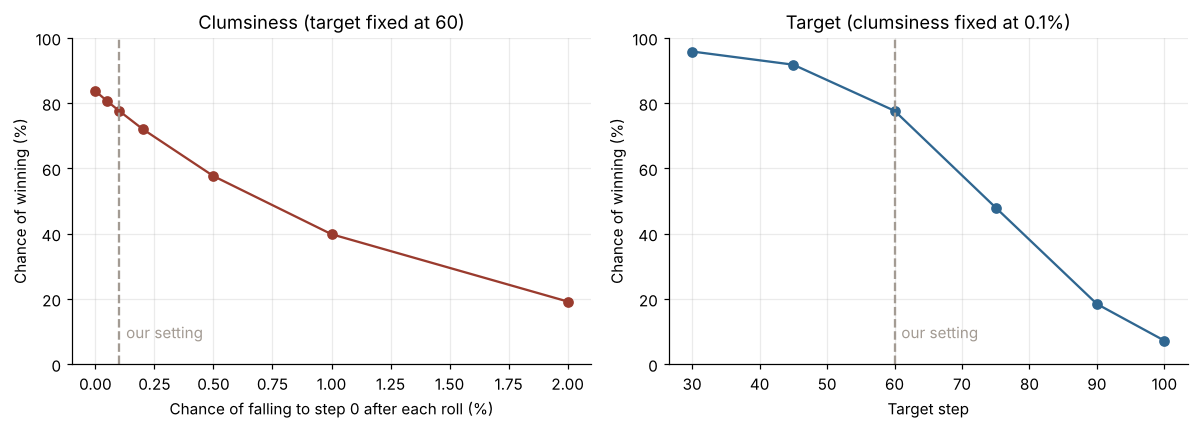

Clumsiness  ->  chance of winning
    0.00%        83.7%
    0.05%        80.6%
    0.10%        77.7%
    0.20%        72.1%
    0.50%        57.7%
    1.00%        39.8%
    2.00%        19.2%
Target  ->  chance of winning
     30        95.8%
     45        91.8%
     60        77.7%
     75        48.0%
     90        18.5%
    100         7.2%


In [8]:
clumsy_values = [0, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.02]
target_values = [30, 45, 60, 75, 90, 100]

by_clumsy = [exact_win_chance(ROLLS, TARGET, c) for c in clumsy_values]
by_target = [exact_win_chance(ROLLS, t, CLUMSY) for t in target_values]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(np.array(clumsy_values) * 100, np.array(by_clumsy) * 100, "o-", color=RED)
axes[0].axvline(CLUMSY * 100, color=GREY, ls="--"); axes[0].text(CLUMSY * 100 + 0.03, 8, "our setting", color=GREY)
axes[0].set_xlabel("Chance of falling to step 0 after each roll (%)")
axes[0].set_ylabel("Chance of winning (%)"); axes[0].set_ylim(0, 100)
axes[0].set_title("Clumsiness (target fixed at 60)")

axes[1].plot(target_values, np.array(by_target) * 100, "o-", color=BLUE)
axes[1].axvline(TARGET, color=GREY, ls="--"); axes[1].text(TARGET + 1, 8, "our setting", color=GREY)
axes[1].set_xlabel("Target step"); axes[1].set_ylabel("Chance of winning (%)"); axes[1].set_ylim(0, 100)
axes[1].set_title("Target (clumsiness fixed at 0.1%)")
plt.tight_layout(); plt.show()

print("Clumsiness  ->  chance of winning")
for c, w in zip(clumsy_values, by_clumsy): print(f"  {c:>7.2%}      {w:>7.1%}")
print("Target  ->  chance of winning")
for t, w in zip(target_values, by_target): print(f"  {t:>5}      {w:>7.1%}")

### How to read it
The left chart changes how clumsy the climber is while the target stays at 60. The right chart changes the target while clumsiness stays at 0.1%. The grey dashed line marks the settings we have used all along.

### What it means
Both settings matter, but clumsiness is the more dangerous one. With no clumsiness at all, the chance of winning is 83.7%. At our 0.1% it drops to 77.7%, and at 1% it falls to 39.8%. A fall of 0.1% sounds tiny, but it is applied 100 times and any single fall erases all your progress. The target works more gently at first (96% for step 30) and then falls quickly past 75: only 18.5% reach step 90, and 7.2% reach step 100.

So a tiny per-roll risk, repeated many times, adds up to a large effect. Over 100 rolls, about 9.5% of climbers are clumsy at least once, and each of those is badly hurt unless it happens very early.

### What's next and why
This notebook built the exact answer and the value map. Notebook 03 takes the simulated results and ask how sure we can be about them: bootstrap intervals, a Bayesian update and hypothesis tests, compared against these exact values.

## 9. Summary

| Question | Answer | Method |
|---|---|---|
| Chance of winning (simulated, 10,000 climbers) | 77.55% (76.7% to 78.4%) | Hacker statistics |
| Chance of winning (exact) | **77.67%** | Markov chain, forward |
| Same number from the value map | 77.67% | Dynamic programming, backward |
| Average finishing step | about 72 | Exact distribution |
| Simulation error with 10,000 climbers | about 0.4 points | Measured against the exact answer |
| No clumsiness at all | 83.7% | Sensitivity analysis |

**Takeaways**
1. Simulation and exact math agree, so the website and notebook 01 are trustworthy.
2. The exact answer costs a few hundred additions; precision from simulation costs millions of dice rolls.
3. A position's value depends on the clock as well as the height.
4. Small repeated risks (0.1% per roll) have a large combined effect.

**Where the code lives:** `src/hacker_stats.py` (functions `exact_distribution`, `value_map`), covered by `tests/test_hacker_stats.py`.